# Task-7 Week-3.

**Dataset :-** 'Admission_Prediction.csv'

**Objective :-Analyze seasonality patterns and long-term trends in historical admissions and enrollment data to forecast future applicant volumes and institutional capacity requirements.

In [24]:
# Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing

In [25]:
# Load the dataset

df = pd.read_csv("Admission_Prediction.csv")

print("Shape:", df.shape)
display(df.head())
print("\nColumns:", df.columns.tolist())

Shape: (1000, 14)


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Year,Application_Date,University_Name,region,Admission Status
0,104,317,104,2,4.5,4.0,8.47,0,0.57,2022,2022-01-03,Indian Institute of Technology Bombay,West,Rejected
1,170,311,99,2,2.5,3.0,7.98,0,0.65,2022,2022-01-09,Indian Institute of Technology Delhi,North,Rejected
2,138,316,100,2,1.5,3.0,8.16,1,0.71,2022,2022-01-12,Indian Institute of Technology Delhi,North,Rejected
3,147,315,105,3,2.0,2.5,8.48,0,0.75,2022,2022-01-13,Indian Institute of Technology Delhi,North,Accepted
4,117,299,102,3,4.0,3.5,8.62,0,0.56,2022,2022-01-14,Indian Institute of Technology Delhi,North,Rejected



Columns: ['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit', 'Year', 'Application_Date', 'University_Name', 'region', 'Admission Status']


In [26]:
# Inspect the data types and missing values.

display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "unique_values": df.nunique(dropna=True)
}))


,dtype,missing_values,unique_values
Serial No.,int64,0,1000
GRE Score,int64,0,51
TOEFL Score,int64,0,29
University Rating,int64,0,5
SOP,float64,0,27
LOR,float64,0,26
CGPA,float64,0,249
Research,int64,0,2
Chance of Admit,float64,0,65
Year,int64,0,5


In [27]:
# Inspect schema, date range, and data quality

# Convert date and year columns safely.
if "Application_Date" not in df.columns:
    raise ValueError("Application_Date column is required for time-series analysis.")

df["Application_Date"] = pd.to_datetime(df["Application_Date"], errors="coerce")
if "Year" in df.columns:
    df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
else:
    df["Year"] = df["Application_Date"].dt.year

df = df.dropna(subset=["Application_Date"]).copy()
df["Year"] = df["Year"].fillna(df["Application_Date"].dt.year).astype(int)
df = df.sort_values("Application_Date").reset_index(drop=True)

print("Date range:", df["Application_Date"].min(), "to", df["Application_Date"].max())
print("Years available:", sorted(df["Year"].unique()))
print("Rows after removing invalid dates:", len(df))
display(df.groupby("Year").size().rename("application_records").to_frame())

Date range: 2022-01-03 00:00:00 to 2026-12-31 00:00:00
Years available: [np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]
Rows after removing invalid dates: 1000


,application_records
Year,
2022,200
2023,200
2024,200
2025,200
2026,200


In [28]:
# Define the outcome fields

if "Admission Status" not in df.columns:
    raise ValueError("Admission Status column is required.")

status = df["Admission Status"].astype(str).str.strip().str.lower()
df["accepted_flag"] = status.map({"accepted": 1, "rejected": 0})

if df["accepted_flag"].isna().any():
    print("Unrecognized admission labels:", df.loc[df["accepted_flag"].isna(), "Admission Status"].unique())
    raise ValueError("Please map all Admission Status labels before continuing.")

print("Acceptance rate:", round(df["accepted_flag"].mean(), 3))
display(df["Admission Status"].value_counts().to_frame("count"))

Acceptance rate: 0.435


,count
Admission Status,
Rejected,565
Accepted,435


In [29]:
# Build monthly and annual time series

# Monthly counts, including zero-application months if there are gaps.
monthly = df.set_index("Application_Date").resample("MS").agg(
    applications=("accepted_flag", "size"),
    accepted=("accepted_flag", "sum"),
)
monthly["rejected"] = monthly["applications"] - monthly["accepted"]
monthly["acceptance_rate"] = monthly["accepted"] / monthly["applications"].replace(0, np.nan)
monthly[["applications", "accepted", "rejected"]] = monthly[["applications", "accepted", "rejected"]].fillna(0)

annual = df.groupby("Year").agg(
    applications=("accepted_flag", "size"),
    accepted=("accepted_flag", "sum"),
)
annual["rejected"] = annual["applications"] - annual["accepted"]
annual["acceptance_rate"] = annual["accepted"] / annual["applications"]

display(monthly.head(12))
display(annual)

,applications,accepted,rejected,acceptance_rate
Application_Date,,,,
2022-01-01,11,5,6,0.454545
2022-02-01,20,9,11,0.450000
2022-03-01,15,6,9,0.400000
2022-04-01,11,5,6,0.454545
2022-05-01,18,7,11,0.388889
2022-06-01,22,12,10,0.545455
2022-07-01,20,5,15,0.250000
2022-08-01,13,9,4,0.692308
2022-09-01,19,10,9,0.526316


,applications,accepted,rejected,acceptance_rate
Year,,,,
2022,200,92,108,0.460
2023,200,88,112,0.440
2024,200,81,119,0.405
2025,200,90,110,0.450
2026,200,84,116,0.420


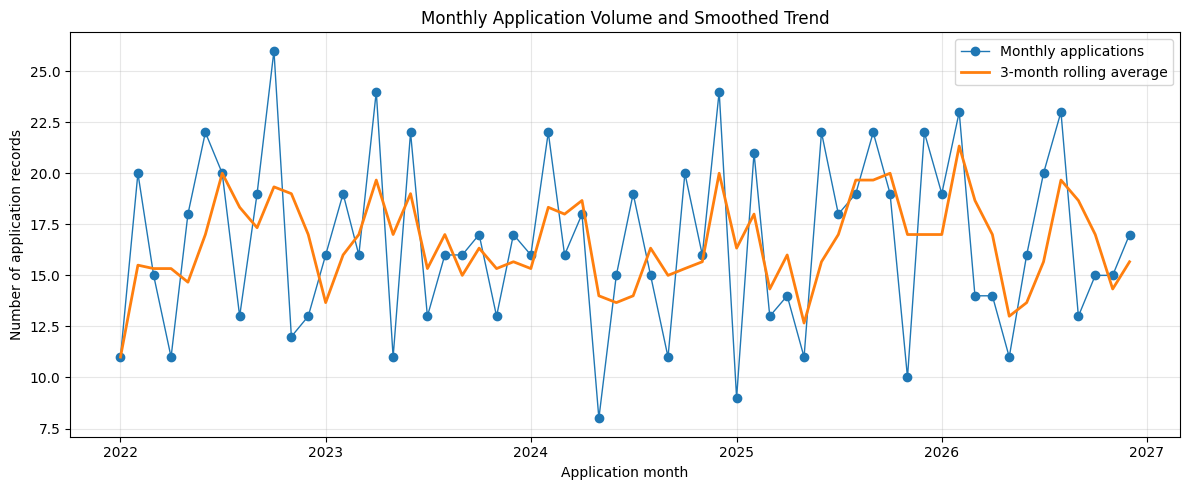

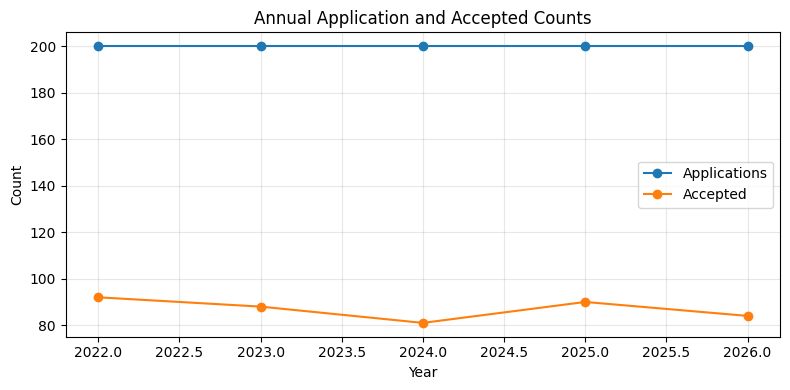

,applications,accepted,rejected,acceptance_rate
Year,,,,
2022,200,92,108,0.460
2023,200,88,112,0.440
2024,200,81,119,0.405
2025,200,90,110,0.450
2026,200,84,116,0.420


In [30]:
# Explore long-term trend in application volume

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly.index, monthly["applications"], marker="o", linewidth=1, label="Monthly applications")
ax.plot(monthly.index, monthly["applications"].rolling(3, min_periods=1).mean(),
        linewidth=2, label="3-month rolling average")
ax.set_title("Monthly Application Volume and Smoothed Trend")
ax.set_xlabel("Application month")
ax.set_ylabel("Number of application records")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(annual.index, annual["applications"], marker="o", label="Applications")
ax.plot(annual.index, annual["accepted"], marker="o", label="Accepted")
ax.set_title("Annual Application and Accepted Counts")
ax.set_xlabel("Year")
ax.set_ylabel("Count")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

display(annual)

,mean_applications,median_applications,std_applications,mean_accepted
Jan,14.2,16.0,4.086563,6.6
Feb,21.0,21.0,1.581139,9.0
Mar,14.8,15.0,1.303840,6.6
Apr,16.2,14.0,5.019960,7.2
May,11.8,11.0,3.701351,5.0
Jun,19.4,22.0,3.577709,9.4
Jul,18.0,19.0,2.915476,6.0
Aug,17.2,16.0,3.898718,7.4
Sep,16.2,16.0,4.438468,9.4
Oct,19.4,19.0,4.159327,8.2


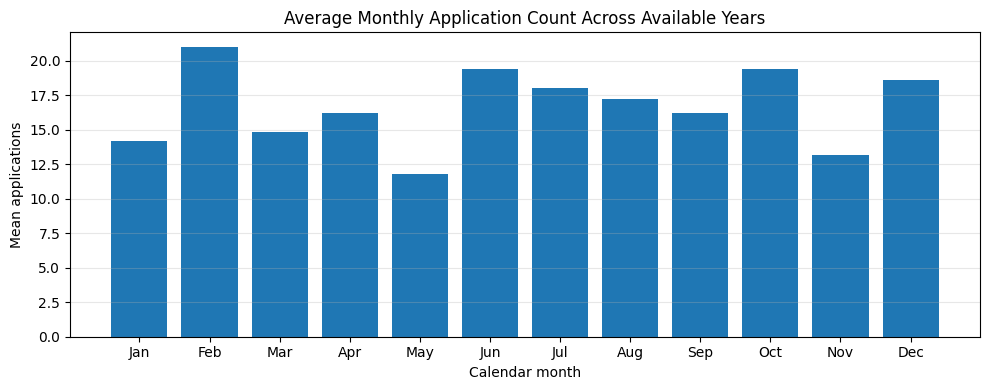

In [31]:
# Examine monthly seasonality

# Compare the distribution of application counts by calendar month across years.
seasonality = monthly.copy()
seasonality["year"] = seasonality.index.year
seasonality["month"] = seasonality.index.month

month_profile = seasonality.groupby("month").agg(
    mean_applications=("applications", "mean"),
    median_applications=("applications", "median"),
    std_applications=("applications", "std"),
    mean_accepted=("accepted", "mean")
).reindex(range(1, 13))
month_profile.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
display(month_profile)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(month_profile.index, month_profile["mean_applications"])
ax.set_title("Average Monthly Application Count Across Available Years")
ax.set_xlabel("Calendar month")
ax.set_ylabel("Mean applications")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

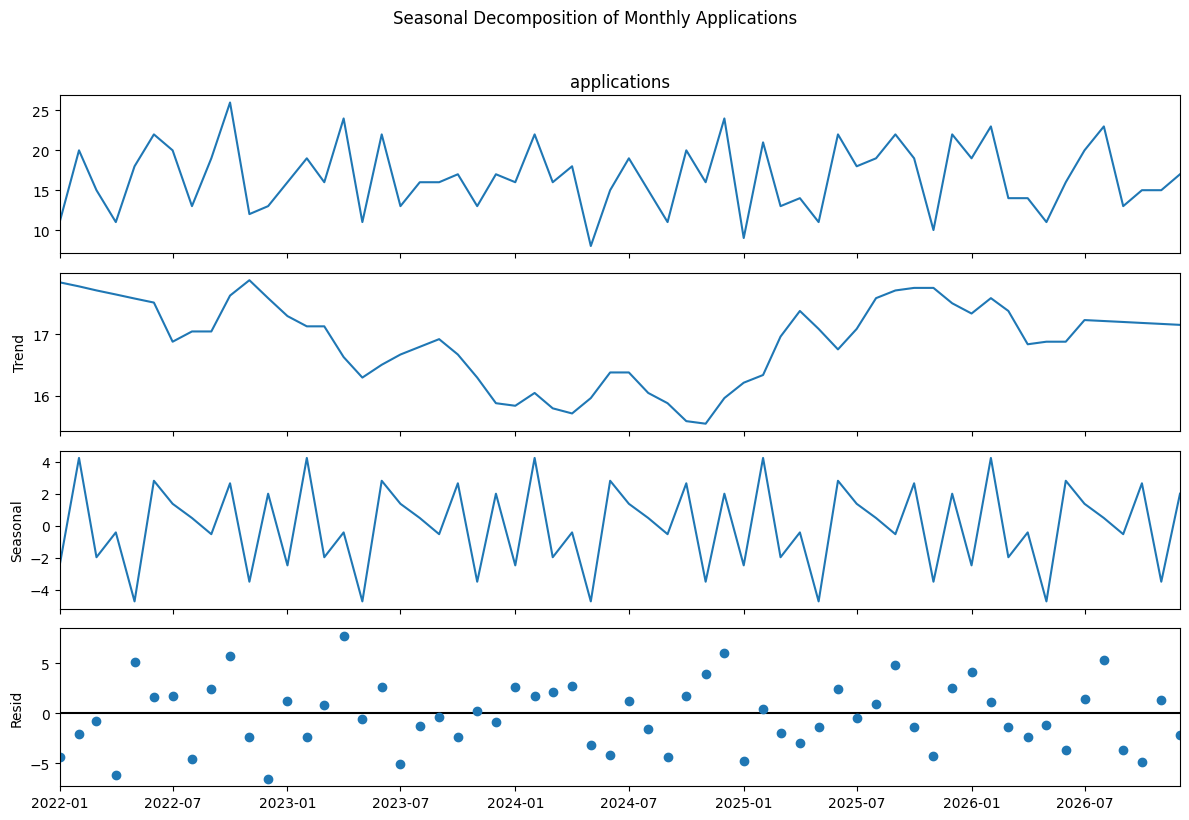

In [32]:
# Optional seasonal decomposition

if len(monthly) >= 24 and monthly["applications"].sum() > 0:
    # Add a small epsilon only for multiplicative decomposition; use additive by default.
    decomp = seasonal_decompose(monthly["applications"].astype(float), model="additive", period=12, extrapolate_trend="freq")
    fig = decomp.plot()
    fig.set_size_inches(12, 8)
    fig.suptitle("Seasonal Decomposition of Monthly Applications", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print(f"Skipping decomposition: {len(monthly)} monthly observations found; at least 24 are recommended.")

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
year,,,,,,,,,,,,
2022,11,20,15,11,18,22,20,13,19,26,12,13
2023,16,19,16,24,11,22,13,16,16,17,13,17
2024,16,22,16,18,8,15,19,15,11,20,16,24
2025,9,21,13,14,11,22,18,19,22,19,10,22
2026,19,23,14,14,11,16,20,23,13,15,15,17


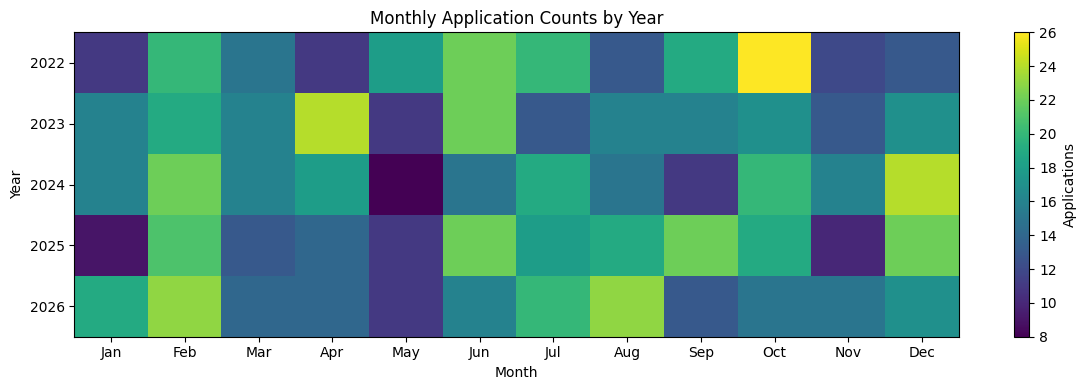

In [33]:
# Check whether apparent seasonality is trustworthy

monthly_pivot = seasonality.pivot_table(index="year", columns="month", values="applications", aggfunc="sum", fill_value=0)
monthly_pivot = monthly_pivot.reindex(columns=range(1, 13), fill_value=0)
monthly_pivot.columns = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
display(monthly_pivot)

fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(monthly_pivot.values, aspect="auto")
ax.set_yticks(range(len(monthly_pivot.index)), labels=monthly_pivot.index)
ax.set_xticks(range(12), labels=monthly_pivot.columns)
ax.set_title("Monthly Application Counts by Year")
ax.set_xlabel("Month")
ax.set_ylabel("Year")
plt.colorbar(im, ax=ax, label="Applications")
plt.tight_layout()
plt.show()

In [34]:
# Forecasting strategy

def seasonal_naive_forecast(series, horizon=12, seasonal_period=12):
    series = series.astype(float)
    if len(series) < seasonal_period:
        return pd.Series([series.mean() if len(series) else 0.0] * horizon)
    last_season = series.iloc[-seasonal_period:].to_numpy()
    reps = int(np.ceil(horizon / seasonal_period))
    return pd.Series(np.tile(last_season, reps)[:horizon])

# Forecast horizon
HORIZON_MONTHS = 12
future_index = pd.date_range(monthly.index.max() + pd.offsets.MonthBegin(1),
                             periods=HORIZON_MONTHS, freq="MS")
print("Forecast months:", future_index.min().date(), "to", future_index.max().date())

Forecast months: 2027-01-01 to 2027-12-01


,model,MAE,RMSE
1,Holt-Winters additive,3.416671,3.915782
0,Seasonal naive,4.000000,5.066228


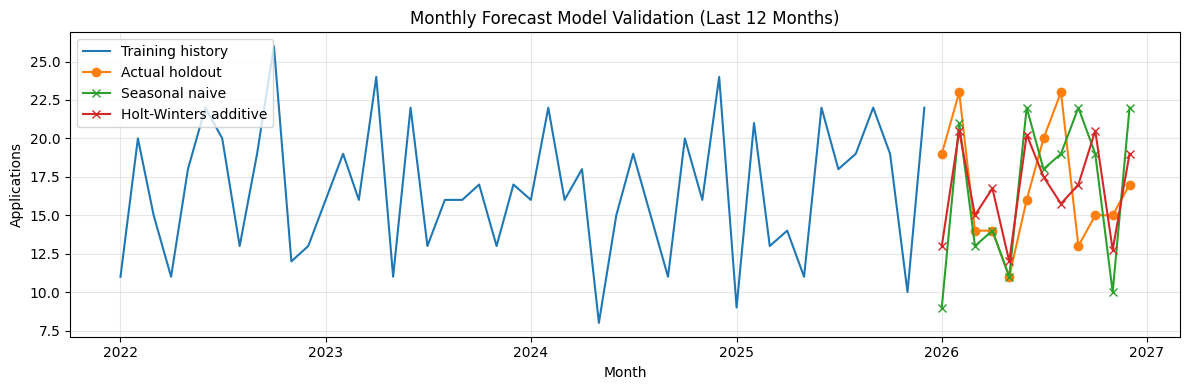

In [35]:
# Compare forecasts with a time-ordered holdout

# Use the last 12 months as holdout only if there is enough history before them.
y = monthly["applications"].astype(float)
if len(y) >= 24:
    train, test = y.iloc[:-12], y.iloc[-12:]
    predictions = {}

    predictions["Seasonal naive"] = seasonal_naive_forecast(train, horizon=len(test), seasonal_period=12).to_numpy()

    try:
        hw = ExponentialSmoothing(
            train, trend="add", seasonal="add", seasonal_periods=12,
            initialization_method="estimated"
        ).fit(optimized=True)
        predictions["Holt-Winters additive"] = hw.forecast(len(test)).to_numpy()
    except Exception as e:
        print("Holt-Winters holdout model could not fit:", e)

    rows = []
    for name, pred in predictions.items():
        pred = np.maximum(0, pred)
        rows.append({
            "model": name,
            "MAE": mean_absolute_error(test, pred),
            "RMSE": mean_squared_error(test, pred) ** 0.5
        })
    validation_results = pd.DataFrame(rows).sort_values("MAE")
    display(validation_results)

    plt.figure(figsize=(12, 4))
    plt.plot(train.index, train, label="Training history")
    plt.plot(test.index, test, marker="o", label="Actual holdout")
    for name, pred in predictions.items():
        plt.plot(test.index, np.maximum(0, pred), marker="x", label=name)
    plt.title("Monthly Forecast Model Validation (Last 12 Months)")
    plt.xlabel("Month")
    plt.ylabel("Applications")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print(f"Only {len(y)} monthly observations. Need at least 24 for a 12-month seasonal holdout; treat forecasts as exploratory.")
    validation_results = pd.DataFrame(columns=["model", "MAE", "RMSE"])

Selected model: Holt-Winters additive


,forecast_month,forecast_applications
0,2027-01-01,14.2
1,2027-02-01,21.0
2,2027-03-01,14.8
3,2027-04-01,16.2
4,2027-05-01,11.8
5,2027-06-01,19.4
6,2027-07-01,18.0
7,2027-08-01,17.2
8,2027-09-01,16.2
9,2027-10-01,19.4


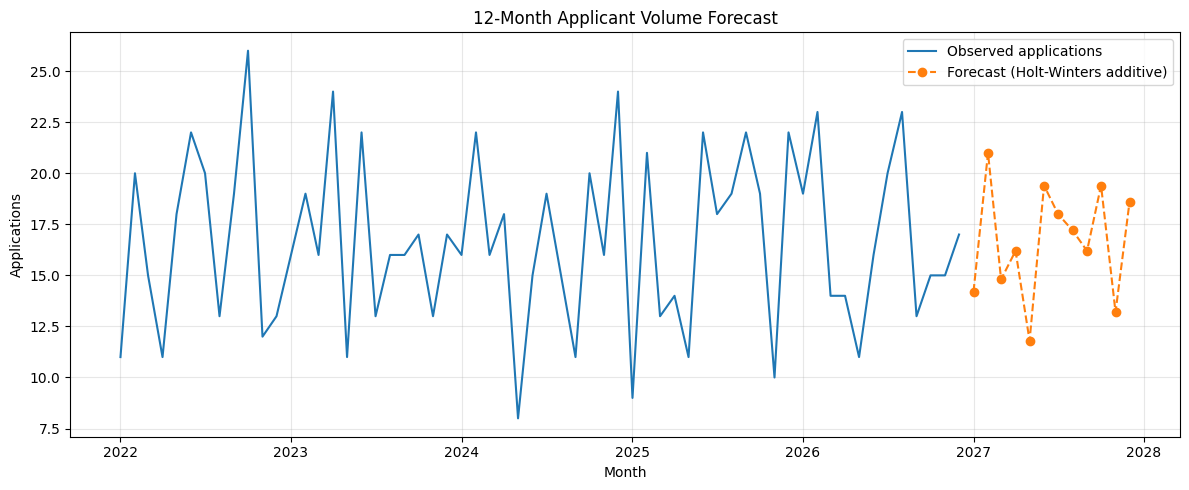

In [36]:
# Fit final model and forecast the next 12 months

y = monthly["applications"].astype(float)

final_model_name = "Seasonal naive"
forecast_values = seasonal_naive_forecast(y, horizon=HORIZON_MONTHS, seasonal_period=12).to_numpy()

if len(y) >= 24:
    try:
        final_hw = ExponentialSmoothing(
            y, trend="add", seasonal="add", seasonal_periods=12,
            initialization_method="estimated"
        ).fit(optimized=True)
        hw_values = final_hw.forecast(HORIZON_MONTHS).to_numpy()

        # Choose Holt-Winters only if validation was possible and its MAE is lower.
        use_hw = False
        if not validation_results.empty:
            best = validation_results.iloc[0]["model"]
            use_hw = (best == "Holt-Winters additive")
        if use_hw:
            forecast_values = hw_values
            final_model_name = "Holt-Winters additive"
    except Exception as e:
        print("Using seasonal-naive fallback:", e)

forecast_values = np.maximum(0, forecast_values)
forecast = pd.DataFrame({
    "forecast_month": future_index,
    "forecast_applications": np.round(forecast_values, 1)
})
print("Selected model:", final_model_name)
display(forecast)

plt.figure(figsize=(12, 5))
plt.plot(y.index, y, label="Observed applications")
plt.plot(forecast["forecast_month"], forecast["forecast_applications"],
         marker="o", linestyle="--", label=f"Forecast ({final_model_name})")
plt.title("12-Month Applicant Volume Forecast")
plt.xlabel("Month")
plt.ylabel("Applications")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

,year,forecast_applications_linear_trend
0,2027,200
1,2028,200
2,2029,200


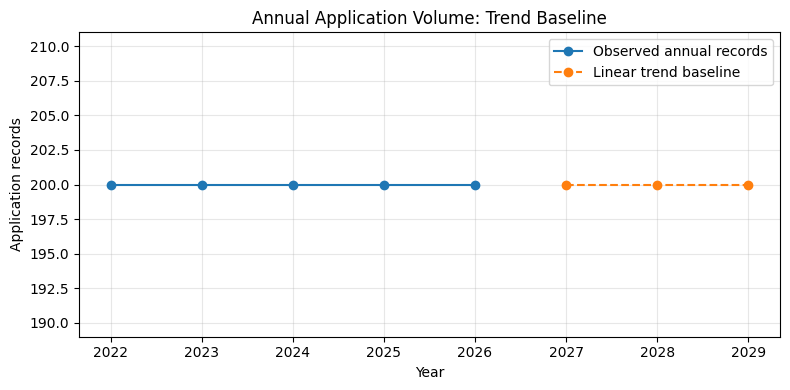

In [37]:
# Forecast annual volume using a simple trend baseline

annual_series = annual["applications"].sort_index()
years = annual_series.index.to_numpy(dtype=float)
counts = annual_series.to_numpy(dtype=float)

if len(annual_series) >= 2:
    slope, intercept = np.polyfit(years, counts, 1)
    future_years = np.arange(int(years.max()) + 1, int(years.max()) + 4)
    annual_pred = np.maximum(0, slope * future_years + intercept)
    annual_forecast = pd.DataFrame({
        "year": future_years.astype(int),
        "forecast_applications_linear_trend": np.round(annual_pred).astype(int)
    })
    display(annual_forecast)

    plt.figure(figsize=(8, 4))
    plt.plot(annual_series.index, annual_series.values, marker="o", label="Observed annual records")
    plt.plot(annual_forecast["year"], annual_forecast["forecast_applications_linear_trend"],
             marker="o", linestyle="--", label="Linear trend baseline")
    plt.title("Annual Application Volume: Trend Baseline")
    plt.xlabel("Year")
    plt.ylabel("Application records")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    annual_forecast = pd.DataFrame()
    print("Not enough annual observations to fit a trend.")

In [38]:
# Translate applications into acceptance and enrollment scenarios

# Explicit planning assumptions — replace with institutional data where available.
YIELD_RATE = 0.60       # assumed share of accepted applicants who enroll
CAPACITY_TARGET = 250   # example available seats; replace with actual capacity
ACCEPTANCE_RATE = float(df["accepted_flag"].mean())

scenario = forecast.copy()
scenario["expected_accepted"] = scenario["forecast_applications"] * ACCEPTANCE_RATE
scenario["expected_enrolled"] = scenario["expected_accepted"] * YIELD_RATE
scenario["capacity_target"] = CAPACITY_TARGET
scenario["seat_surplus_or_shortfall"] = CAPACITY_TARGET - scenario["expected_enrolled"]
scenario["capacity_status"] = np.where(
    scenario["expected_enrolled"] > CAPACITY_TARGET, "Potential shortfall", "Within assumed capacity"
)
display(scenario.round(1))

,forecast_month,forecast_applications,expected_accepted,expected_enrolled,capacity_target,seat_surplus_or_shortfall,capacity_status
0,2027-01-01,14.2,6.2,3.7,250,246.3,Within assumed capacity
1,2027-02-01,21.0,9.1,5.5,250,244.5,Within assumed capacity
2,2027-03-01,14.8,6.4,3.9,250,246.1,Within assumed capacity
3,2027-04-01,16.2,7.0,4.2,250,245.8,Within assumed capacity
4,2027-05-01,11.8,5.1,3.1,250,246.9,Within assumed capacity
5,2027-06-01,19.4,8.4,5.1,250,244.9,Within assumed capacity
6,2027-07-01,18.0,7.8,4.7,250,245.3,Within assumed capacity
7,2027-08-01,17.2,7.5,4.5,250,245.5,Within assumed capacity
8,2027-09-01,16.2,7.0,4.2,250,245.8,Within assumed capacity
9,2027-10-01,19.4,8.4,5.1,250,244.9,Within assumed capacity


,forecast_month,forecast_applications,expected_accepted,enrolled_low,enrolled_base,enrolled_high,capacity_target
0,2027-01-01,14.2,6.2,2.8,3.7,4.6,250
1,2027-02-01,21.0,9.1,4.1,5.5,6.9,250
2,2027-03-01,14.8,6.4,2.9,3.9,4.8,250
3,2027-04-01,16.2,7.0,3.2,4.2,5.3,250
4,2027-05-01,11.8,5.1,2.3,3.1,3.8,250
5,2027-06-01,19.4,8.4,3.8,5.1,6.3,250
6,2027-07-01,18.0,7.8,3.5,4.7,5.9,250
7,2027-08-01,17.2,7.5,3.4,4.5,5.6,250
8,2027-09-01,16.2,7.0,3.2,4.2,5.3,250
9,2027-10-01,19.4,8.4,3.8,5.1,6.3,250


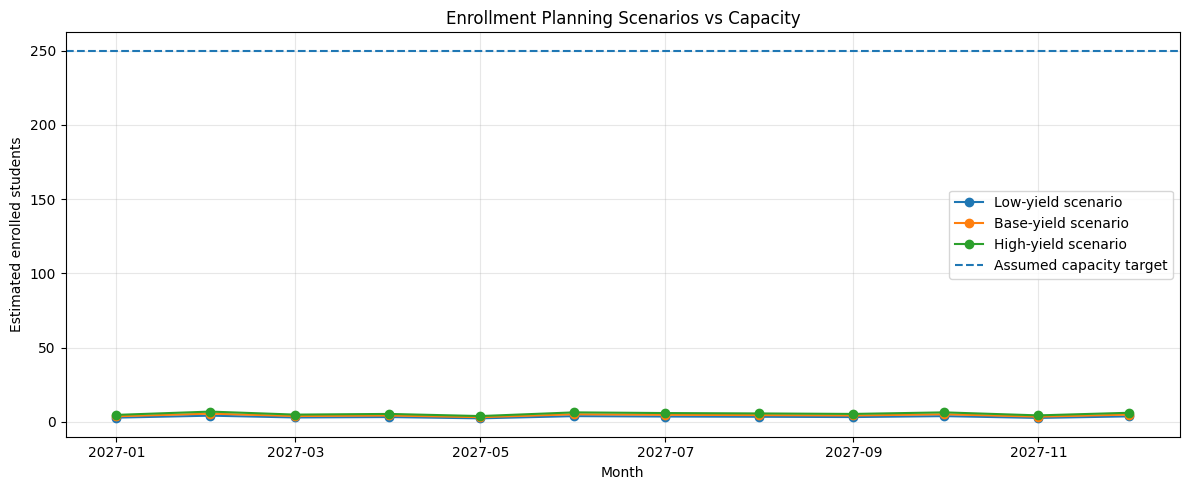

In [39]:
# Scenario interpretation

# Low/base/high planning scenarios using adjustable assumptions.
LOW_YIELD = 0.45
BASE_YIELD = YIELD_RATE
HIGH_YIELD = 0.75

scenario_range = forecast[["forecast_month", "forecast_applications"]].copy()
scenario_range["expected_accepted"] = scenario_range["forecast_applications"] * ACCEPTANCE_RATE
scenario_range["enrolled_low"] = scenario_range["expected_accepted"] * LOW_YIELD
scenario_range["enrolled_base"] = scenario_range["expected_accepted"] * BASE_YIELD
scenario_range["enrolled_high"] = scenario_range["expected_accepted"] * HIGH_YIELD
scenario_range["capacity_target"] = CAPACITY_TARGET
display(scenario_range.round(1))

plt.figure(figsize=(12, 5))
plt.plot(scenario_range["forecast_month"], scenario_range["enrolled_low"], marker="o", label="Low-yield scenario")
plt.plot(scenario_range["forecast_month"], scenario_range["enrolled_base"], marker="o", label="Base-yield scenario")
plt.plot(scenario_range["forecast_month"], scenario_range["enrolled_high"], marker="o", label="High-yield scenario")
plt.axhline(CAPACITY_TARGET, linestyle="--", label="Assumed capacity target")
plt.title("Enrollment Planning Scenarios vs Capacity")
plt.xlabel("Month")
plt.ylabel("Estimated enrolled students")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [40]:
# Optional university-level analysis

if "University_Name" in df.columns:
    university_summary = df.groupby("University_Name").agg(
        applications=("accepted_flag", "size"),
        accepted=("accepted_flag", "sum"),
        acceptance_rate=("accepted_flag", "mean")
    ).sort_values("applications", ascending=False)
    display(university_summary)
else:
    print("University_Name column not available; skipping institution-level breakdown.")

,applications,accepted,acceptance_rate
University_Name,,,
National Institute of Technology Warangal,32,14,0.437500
Jamia Millia Islamia,31,15,0.483871
Indian Institute of Technology Kharagpur,31,12,0.387097
University of Madras,30,11,0.366667
Indian Institute of Technology Roorkee,28,12,0.428571
Kalinga Institute of Industrial Technology,26,8,0.307692
Indian Institute of Technology Indore,26,11,0.423077
Amrita Vishwa Vidyapeetham,26,10,0.384615
Visvesvaraya Technological University,26,12,0.461538


In [41]:
# Export tables for reporting

monthly.to_csv("monthly_admissions_summary.csv", index_label="month")
annual.to_csv("annual_admissions_summary.csv")
forecast.to_csv("monthly_applicant_forecast.csv", index=False)
scenario.to_csv("capacity_planning_base_scenario.csv", index=False)
scenario_range.to_csv("capacity_planning_scenarios.csv", index=False)

print("Saved:")
print("- monthly_admissions_summary.csv")
print("- annual_admissions_summary.csv")
print("- monthly_applicant_forecast.csv")
print("- capacity_planning_base_scenario.csv")
print("- capacity_planning_scenarios.csv")

Saved:
- monthly_admissions_summary.csv
- annual_admissions_summary.csv
- monthly_applicant_forecast.csv
- capacity_planning_base_scenario.csv
- capacity_planning_scenarios.csv
